# IS 4487 Assignment 5: Exploratory Data Analysis (EDA) with Stakeholder Framing

In this assignment, you will:
- Load and explore a hotel bookings dataset
- Identify stakeholder needs and frame your analysis around business goals
- Practice data summarization and visualization
- Draw insights that could lead to actionable business recommendations

## Why This Matters

These skills are essential for business majors and minors working in areas like marketing, operations, finance, or consulting. Understanding how to explore and communicate data-driven insights helps you make better decisions and contribute to real-world business outcomes.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_05_eda.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.


## 1. Setup and Data Loading

Instructions:
- Import `pandas`, `seaborn`, and `matplotlib.pyplot`.
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows to confirm it loaded correctly.


In [8]:
# Your code to import libraries and load data goes here
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

hotels=pd.read_csv("hotels.csv")
hotels.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Stakeholder and Business Context

### Business framing:  

Every analysis should serve a decision-maker. Before you explore the data, identify who cares about hotel booking behavior and what they might want to know. Your analysis should be framed around those needs.

### Reflection:
1. Who are the key stakeholders for this dataset?
2. What goals might each stakeholder have?
3. What is a clear, specific business problem statement that this data can help answer?





### ✍️ Your Response: 🔧
1. Hotel managers, revenue managers, and marketing teams are the main stakeholders because they use booking information to make decisions about hotel performance, pricing, and customers.

2. Hotel managers may want to improve occupancy and reduce cancellations. Revenue managers may want to understand booking trends and improve revenue. Marketing teams may want to identify different customer segments and understand their booking behaviors.

3. How can city and resort hotels identify the booking characteristics associated with cancellations so they can better understand customer behavior and improve occupancy and revenue?




## 3. Explore Data Structure and Quality

### Business framing:  

Before diving into analysis, analysts need to understand the shape and health of the data. Bad data leads to bad decisions.

### Do the following:
- Perform the following 3 checks to see the data quality:
  - Summary the data (e.g., `.info()`, `.describe()`)
  - Find the number of Null values
  - Find the number of duplicate row checks


In [9]:
hotels.info()
hotels.describe()

hotels.isnull().sum()

hotels.duplicated().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9404 entries, 0 to 9403
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           9404 non-null   object 
 1   is_canceled                     9404 non-null   int64  
 2   lead_time                       9404 non-null   int64  
 3   arrival_date_year               9404 non-null   int64  
 4   arrival_date_month              9404 non-null   object 
 5   arrival_date_week_number        9404 non-null   int64  
 6   arrival_date_day_of_month       9404 non-null   int64  
 7   stays_in_weekend_nights         9404 non-null   int64  
 8   stays_in_week_nights            9404 non-null   int64  
 9   adults                          9404 non-null   int64  
 10  children                        9404 non-null   int64  
 11  babies                          9404 non-null   int64  
 12  meal                            94

np.int64(1674)

### Reflection:
1. Name at least one structure issue you’ve found (e.g., missing values, formatting problems).
2. How can you fix this structural issue?

### ✍️ Your Response: 🔧
1. One structural issue is that the dataset contains missing values. For example, the country, agent, and company columns do not have values for every booking.

2. I could fix this by determining why the values are missing and then either filling them with an appropriate value, such as "Unknown", or removing columns or rows with too many missing values if they are not useful for the analysis.



## 4. Univariate Analysis

### Business framing:  

Hotels care about trends like average stay length, customer mix, and pricing. A good EDA starts with understanding single variables and their distribution.

### Do the following:
- Select at least 3 individual variables to explore
- Use plots and summary methods (e.g. info(), describe(), etc)  to describe the distribution (hint: we are only looking at the values of one variable, so think of plots you've used in the past that DON'T compare 2 variables.)
- Focus on what matters from a business standpoint (e.g., pricing, cancellations, guest types)

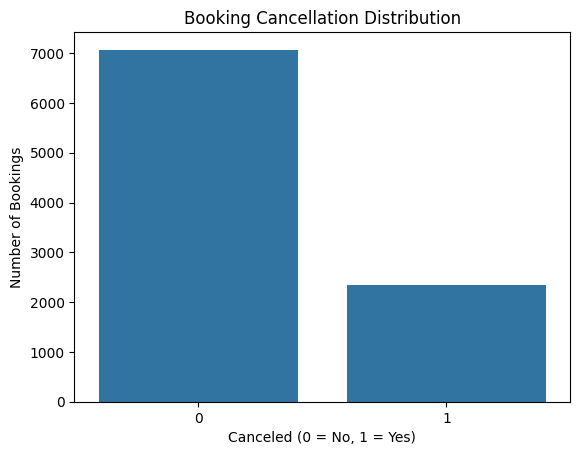

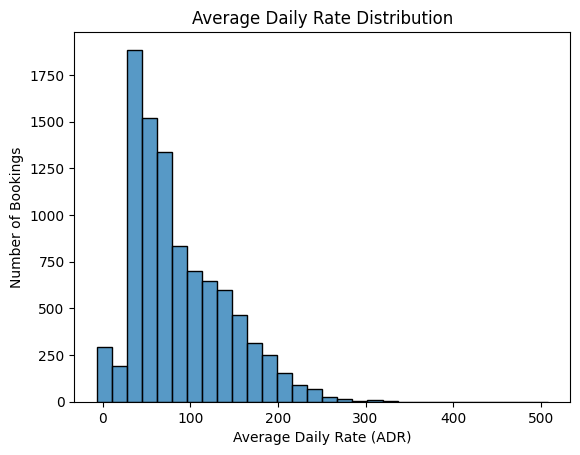

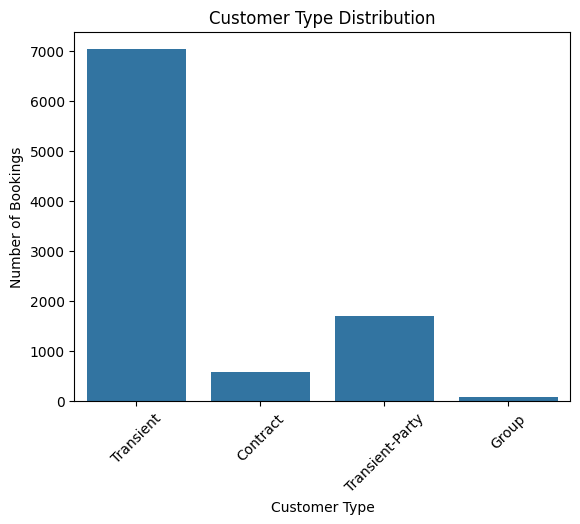

Cancellation Counts:
is_canceled
0    7069
1    2335
Name: count, dtype: int64

ADR Summary:
count    9404.000000
mean       86.843614
std        53.759940
min        -6.380000
25%        45.000000
50%        71.550000
75%       120.600000
max       508.000000
Name: adr, dtype: float64

Customer Type Counts:
customer_type
Transient          7031
Transient-Party    1703
Contract            581
Group                89
Name: count, dtype: int64


In [10]:
# Your code for univariate analysis (e.g., plots, value counts) 🔧
sns.countplot(x='is_canceled', data=hotels)
plt.title('Booking Cancellation Distribution')
plt.xlabel('Canceled (0 = No, 1 = Yes)')
plt.ylabel('Number of Bookings')
plt.show()

sns.histplot(hotels['adr'], bins=30)
plt.title('Average Daily Rate Distribution')
plt.xlabel('Average Daily Rate (ADR)')
plt.ylabel('Number of Bookings')
plt.show()

sns.countplot(x='customer_type', data=hotels)
plt.title('Customer Type Distribution')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.show()

print("Cancellation Counts:")
print(hotels['is_canceled'].value_counts())

print("\nADR Summary:")
print(hotels['adr'].describe())

print("\nCustomer Type Counts:")
print(hotels['customer_type'].value_counts())


### Reflection:
1. Variable 1 – What did you explore and what did you find?
2. Variable 2 – What did you explore and what did you find?
3. Variable 3 – What did you explore and what did you find?

### ✍️ Your Response: 🔧
- **Variable 1 – Summary and insights:** I explored booking cancellations and found that 7,069 bookings were not canceled while 2,335 were canceled. This means about 25% of the bookings were canceled, showing that cancellations are a significant issue for the hotels.
- **Variable 2 – Summary and insights:**  I explored average daily rate (ADR) and found that the average was about $86.84, with a median of 71.55 dollars. Most rates were on the lower end, but there were some unusually high and low values that could be worth looking into further.
- **Variable 3 – Summary and insights:**  I explored customer type and found that transient customers made up the majority of bookings with 7,031. Transient-Party customers were the next largest group with 1,703, while Contract and Group customers were much less common.


## 5. Bivariate Analysis

### Business framing:  

Stakeholders often ask: “What drives cancellations?” or “Do longer stays mean higher revenue?” Bivariate analysis helps you uncover those kinds of relationships.

### Do the following:
- Choose 2 relevant variable pairs (e.g., `lead_time` vs. `is_canceled`, or `adr` vs. `customer_type`)
- Use scatterplots, grouped bar plots, or boxplots to explore the relationships
- Interpret what these relationships could mean for the hotel business

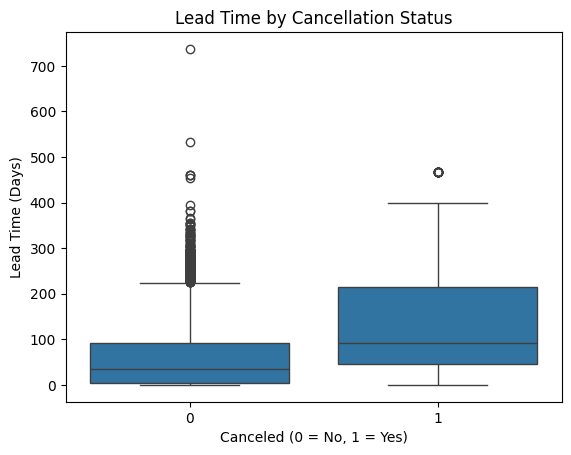

Average Lead Time by Cancellation Status:
is_canceled
0     63.885132
1    126.072805
Name: lead_time, dtype: float64


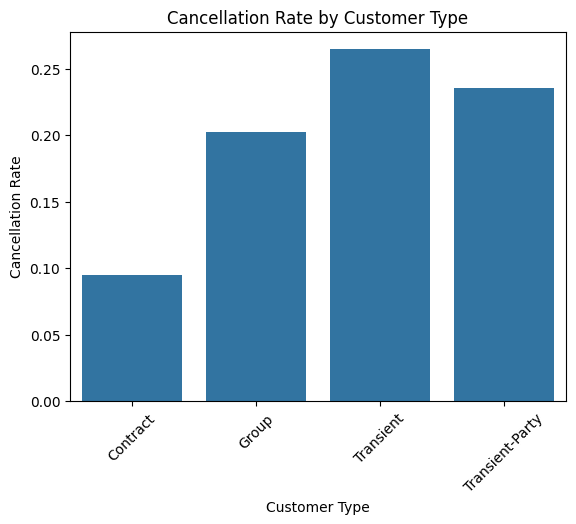


Cancellation Rate by Customer Type:
     customer_type  is_canceled
0         Contract     0.094664
1            Group     0.202247
2        Transient     0.264685
3  Transient-Party     0.235467


In [11]:
# Your code to analyze variable relationships (e.g., scatterplots, grouped bars) 🔧
sns.boxplot(x='is_canceled', y='lead_time', data=hotels)
plt.title('Lead Time by Cancellation Status')
plt.xlabel('Canceled (0 = No, 1 = Yes)')
plt.ylabel('Lead Time (Days)')
plt.show()

print("Average Lead Time by Cancellation Status:")
print(hotels.groupby('is_canceled')['lead_time'].mean())

cancellation_rates = hotels.groupby('customer_type')['is_canceled'].mean().reset_index()

sns.barplot(x='customer_type', y='is_canceled', data=cancellation_rates)
plt.title('Cancellation Rate by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Cancellation Rate')
plt.xticks(rotation=45)
plt.show()

print("\nCancellation Rate by Customer Type:")
print(cancellation_rates)

### Reflection:
1. Relationship 1 – What did you analyze and what insights did you find?
2. Relationship 2 – What did you analyze and what insights did you find?

### ✍️ Your Response: 🔧
- **Relationship 1:**  I looked at booking dates compared to cancelations, what I found was on average customers that booked 64 days or less out from their stay dont't cancel but those that book more than 126 days out are more likely to cancel.
- **Relationship 2:**  The other relationship that I looked at was cancelations by customer type, I found that a little over 1/4 cancellations came from transient-party, meaning that those bookings seem to be the highest risk.


## 6. Problem Complexity and Analytics Framing

### Business framing:  

Let’s say you found a strong trend — maybe high lead times predict cancellations, or certain channels bring repeat guests. What kind of problem is this?

- Choose one insight from your earlier analysis
- Reflect on:
  - What type of complexity this problem represents (e.g., variety, volume, variability)
  - What kind of analytics would help solve or explain it (descriptive, diagnostic, predictive, prescriptive)

### Reflection:
1. What was your selected insight?
2. What kind of complexity does it involve?
3. What type of analytics would help, and why?



### ✍️ Your Response: 🔧
1. My insight was that bookings with higher lead times were more likely to cancel.
2. Variability, because a customer could book at any point from day of to hundreds of days out.
3. Predictive analytics would help because the hotel could use lead time and past cancellation behavior to estimate the likelihood that a future reservation will be canceled.



## 7. Final Takeaways and Recommendations

### Business framing:  

Imagine you’re preparing for a stakeholder meeting. What would you highlight from your findings?

### Reflection:
- 1. What patterns or trends stood out?
- 2. How do they connect to stakeholder goals?
- 3. What recommendation would you make based on this analysis?
- 4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The biggest pattern I found was that bookings with longer lead times were more likely to be canceled. Canceled bookings had an average lead time of about 126 days compared to about 64 days for bookings that were not canceled.

2. Understanding which reservations are more likely to cancel could help managers make better planning decisions.

3. I would recommend that hotels pay closer attention to reservations made far in advance and use historical lead-time patterns when forecasting cancellations and occupancy.

4. This relates to my learning outcome of turning business questions into measurable variables. I took the question of what might be related to cancellations and analyzed lead time as a measurable variable. I can use the same process with renovation projects by turning questions about which improvements are worth the investment into variables that can be analyzed for ROI.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [5]:
!jupyter nbconvert --to html "assignment_05_eda.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_05_eda.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execu